# Colorado River Basin: Hydrologic Accounting, River Topology & Flow Regimes

**Author:** Douglas Schoch • **Course:** DAT1001: Introduction to Data Science (Colorado Mountain College)  
**Data Sources:** USGS NWIS, USBR Reclamation HydroData, `data/colorado_river_basin.db`, `web/data/*.json`

### Problem Statement & Research Objective
Statutory water apportionments under the **1922 Colorado River Compact** and **1944 Mexican Water Treaty** allocate **16.50–17.50 MAF/yr** (plus ~1.50 MAF/yr in uncounted reservoir evaporation and transit losses), based on abnormally wet 1905–1922 streamgage records. Across the 104-year record (1922–2025) and especially the post-2000 drought (~12.3–12.5 MAF/yr natural flow), physical "wet water" falls chronically short of legal "paper water" claims. This notebook demonstrates the complete end-to-end Python, SQLite, and machine learning workflow behind the Colorado River Basin analytical portal.

| Project Artifact | Live Web Link | Local Repository Path |
|---|---|---|
| **Interactive Dashboard** | [schochdo.github.io/colorado_river](https://schochdo.github.io/colorado_river/index.html) | [`../index.html`](../index.html) |
| **Complete AI Prompt & Screenshot Archive** | [AI Prompt Archive (Live)](https://schochdo.github.io/colorado_river/ai_complete_prompt_archive.html) | [`../ai_complete_prompt_archive.html`](../ai_complete_prompt_archive.html) |
| **Architecture & Methodology Guide** | [Methodology (Live)](https://schochdo.github.io/colorado_river/methodology.html) | [`../methodology.html`](../methodology.html) |
| **Source Code, AI Log & Changelog** | [github.com/schochdo/CO_River](https://github.com/schochdo/CO_River) | [`../AI_LOG.md`](../AI_LOG.md) • [`../CHANGELOG.md`](../CHANGELOG.md) |


## 1. Environment & Dimensional Framework

- **Instantaneous Rate ($Q$, `cfs`):** Real-time weather pulses, dam releases, and operational routing.
- **Annual Volume ($V$, `MAF/yr`):** Multi-year water budget accounting. Bridge: $1\text{ cfs sustained for 1 year} = 723.97\text{ AF} \approx 0.000724\text{ MAF}$.
- **Confluence Rule:** $Q_{\text{downstream}} \approx Q_{\text{upstream}} + Q_{\text{tributary}} - Q_{\text{diversion}} - Q_{\text{loss}}$.


In [1]:
import os, json, sqlite3, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DB_PATH = os.path.join(BASE_DIR, 'data', 'colorado_river_basin.db')
WEB_DATA_DIR = os.path.join(BASE_DIR, 'web', 'data')

# Muted Colorado River corridor palette matching the web portal
CORRIDOR = {
    'blue': '#2b5c8f',
    'ochre': '#c26d2d',
    'sage': '#3f6f58',
    'red': '#9e3f32',
    'ink': '#0f172a',
    'slate': '#475569',
    'sand': '#f5f2eb',
}

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Inter', 'DejaVu Sans', 'Arial'],
    'axes.edgecolor': '#cfc8ba',
    'axes.linewidth': 1.0,
    'axes.labelcolor': '#1e293b',
    'xtick.color': '#475569',
    'ytick.color': '#475569',
    'figure.facecolor': '#ffffff',
    'axes.facecolor': '#faf8f4',
})
print(f'Database found: {os.path.exists(DB_PATH)} | SQLite v{sqlite3.sqlite_version}')


Database found: True | SQLite v3.54.1


## 2. Geospatial River Network & Cataract Canyon Re-Emergence

Inspects the compiled 83-feature topological network (`web/data/river_network.json`) across free-flowing mainstem reaches, submerged reservoir thalwegs, trans-basin diversions, and the Cataract Canyon dynamic re-emergence threshold relative to Lake Powell's surface elevation.


In [2]:
with open(os.path.join(WEB_DATA_DIR, 'river_network.json')) as f:
    net = json.load(f)

props = [feat['properties'] for feat in net['features']]
df_net = pd.DataFrame(props)
print(f'Total network features: {len(df_net)}')
print(df_net.groupby('category')['name'].count().rename('feature_count').to_frame())

def eval_reemergence(powell_elev_ft=3560.0):
    sub = df_net[df_net['minelev_ft'].notna()][['name', 'minelev_ft', 'maxelev_ft']].head(6).copy()
    sub['status'] = np.where(sub['minelev_ft'] > powell_elev_ft, 'Re-emerged Rapids', 'Submerged in Reservoir')
    return sub

print('\nDynamic Cataract / Glen Canyon Threshold Check at Powell = 3,560 ft:')
print(eval_reemergence(3560.0).to_string(index=False))


Total network features: 83
                 feature_count
category                      
mainstem                    20
major_tributary             34
minor_tributary             22
submerged_path               7

Dynamic Cataract / Glen Canyon Threshold Check at Powell = 3,560 ft:
                                                                               name  minelev_ft  maxelev_ft            status
Little Colorado River - Headwaters through Cameron Gorge to Grand Canyon Confluence      4000.0      4200.0 Re-emerged Rapids
                        Virgin River - Headwaters through Virgin Gorge to Lake Mead      4000.0      4200.0 Re-emerged Rapids
                                  White River - Flat Tops to Green River Confluence      4000.0      4200.0 Re-emerged Rapids
     Roaring Fork River - Aspen through Basalt to Colorado River (Glenwood Springs)      4000.0      4200.0 Re-emerged Rapids
                                    San Juan River - Headwaters to Navajo Reservoir    

## 3. Live USGS NWIS Telemetry & Sequential Reach Deltas

Queries live discharge (`00060`) at Lees Ferry (`09380000`) with automatic offline fallback, then computes sequential reach gains/losses (`cfs`) from the cached station snapshot (`web/data/latest_metrics.json`).


In [3]:
def fetch_lees_ferry_live():
    url = 'https://waterservices.usgs.gov/nwis/iv/'
    params = {'sites': '09380000', 'parameterCd': '00060', 'siteStatus': 'active', 'format': 'json'}
    headers = {'User-Agent': 'ColoradoRiverAnalysis-DouglasSchoch/1.0'}
    try:
        r = requests.get(url, params=params, headers=headers, timeout=6)
        r.raise_for_status()
        ts = r.json()['value']['timeSeries'][0]['values'][0]['value'][0]
        return float(ts['value']), ts['dateTime'], 'LIVE USGS NWIS'
    except Exception:
        with open(os.path.join(WEB_DATA_DIR, 'latest_metrics.json')) as f:
            lm = json.load(f)
        by_id = {s['id']: s for s in lm.get('streamflows', [])}
        q = by_id.get('09380000', {}).get('flow_cfs', 8100.0)
        return q, lm.get('fetched_at', 'cached'), 'OFFLINE CACHE'

q_lf, ts_lf, src_lf = fetch_lees_ferry_live()
print(f'Lees Ferry (09380000): {q_lf:,.0f} cfs | Timestamp: {ts_lf} | Source: {src_lf}')

with open(os.path.join(WEB_DATA_DIR, 'latest_metrics.json')) as f:
    lm = json.load(f)

by_id = {s['id']: s for s in lm.get('streamflows', [])}
reach_ids = ['09095500', '09180500', '09380000', '09402500', '09429490']
rows = []
prev_q = None
for sid in reach_ids:
    rec = by_id.get(sid)
    if not rec:
        continue
    q = rec.get('flow_cfs')
    delta = (q - prev_q) if (q is not None and prev_q is not None) else None
    rows.append({'site_id': sid, 'station': rec.get('name'), 'flow_cfs': q, 'reach_delta_cfs': delta})
    if q is not None:
        prev_q = q

print('\nMainstem Sequential Reach Snapshot:')
print(pd.DataFrame(rows).to_string(index=False))


Lees Ferry (09380000): 5,640 cfs | Timestamp: 2026-11-22T10:00:00.000-07:00 | Source: LIVE USGS NWIS

Mainstem Sequential Reach Snapshot:
 site_id                                              station  flow_cfs  reach_delta_cfs
09095500                        Colorado River near Cameo, CO    1180.0              NaN
09180500                        Colorado River near Cisco, UT    2960.0           1780.0
09380000                     Colorado River at Lees Ferry, AZ    5640.0           2680.0
09402500 Colorado River near Grand Canyon, AZ (Phantom Ranch)    8940.0           3300.0


## 4. Relational SQLite Schema & Compliance Queries

Connects to `data/colorado_river_basin.db` and queries `view_reservoir_system_summary` and rolling 10-year Compact delivery totals at Lees Ferry.


In [4]:
conn = sqlite3.connect(DB_PATH)
tables = pd.read_sql_query("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name", conn)
print(tables.to_string(index=False))

summary = pd.read_sql_query('SELECT * FROM view_reservoir_system_summary', conn)
print('\nSystem Storage Summary:')
print(summary.to_string(index=False))

compliance = pd.read_sql_query('''
    SELECT
        CASE
            WHEN water_year < 1960 THEN '1922-1959 (Early)'
            WHEN water_year < 2000 THEN '1960-1999 (Fill/Wet)'
            ELSE '2000-2025 (Millennium Drought)'
        END AS era,
        COUNT(*) AS years,
        ROUND(AVG(natural_flow_maf), 2) AS avg_natural_maf,
        ROUND(AVG(annual_surplus_deficit_maf), 2) AS avg_balance_maf
    FROM view_compact_surplus_deficit
    GROUP BY era
''', conn)
print('\nMulti-Decadal Flow by Era:')
print(compliance.to_string(index=False))


                         name  type
            annual_lees_ferry table
               ingestion_runs table
               rbi_flashiness table
                   reservoirs table
         reservoirs_telemetry table
              sqlite_sequence table
                     stations table
             telemetry_latest table
 view_compact_surplus_deficit  view
  view_live_station_telemetry  view
view_reservoir_system_summary  view

System Storage Summary:
 total_reservoirs  total_capacity_maf  current_storage_maf  system_percent_full  total_dead_pool_maf
               11               60.15                21.95                 36.5                 0.15

Multi-Decadal Flow by Era:
                           era  years  avg_natural_maf  avg_balance_maf
             1922-1959 (Early)     38            13.74            -2.76
          1960-1999 (Fill/Wet)     40            14.61            -1.89
2000-2025 (Millennium Drought)     26            11.76            -4.74


## 5. 104-Year Compact Accounting & Reservoir Buffer Depletion

Visualizes the 1922–2025 naturalized flow series against statutory Compact allocations (15.0 MAF/yr US + 1.5 MAF/yr Mexico Treaty = 16.5 MAF/yr) alongside active storage capacity across the basin's largest reservoirs.


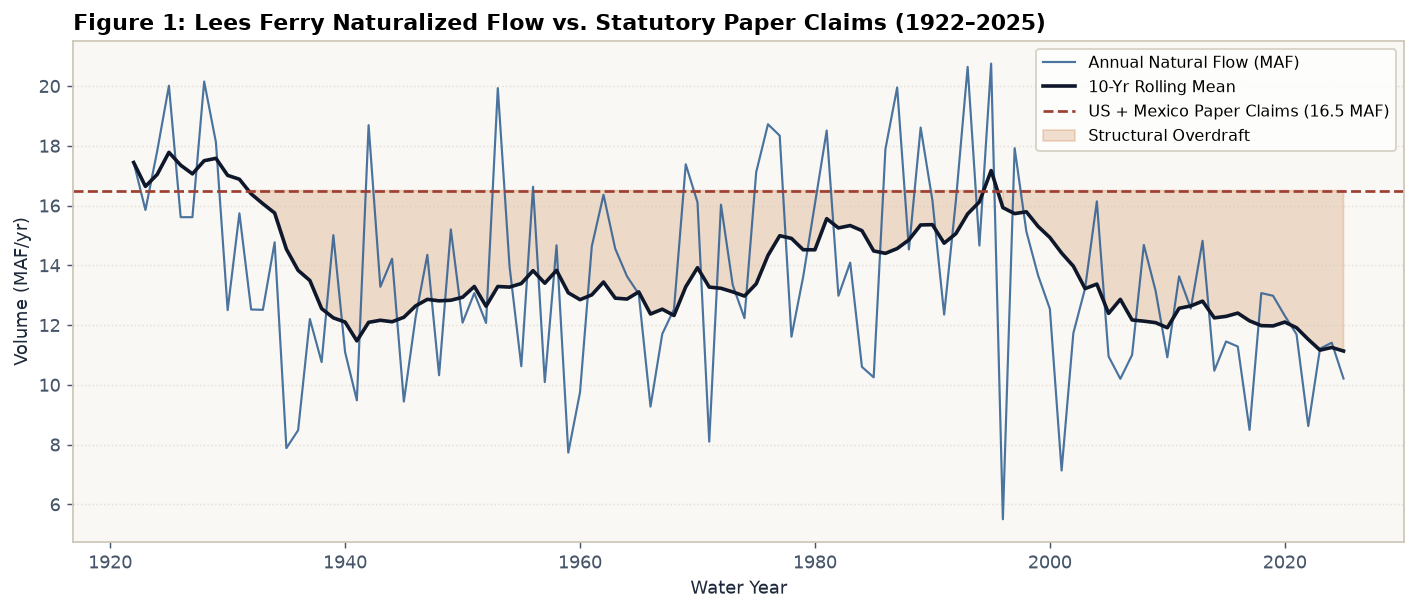

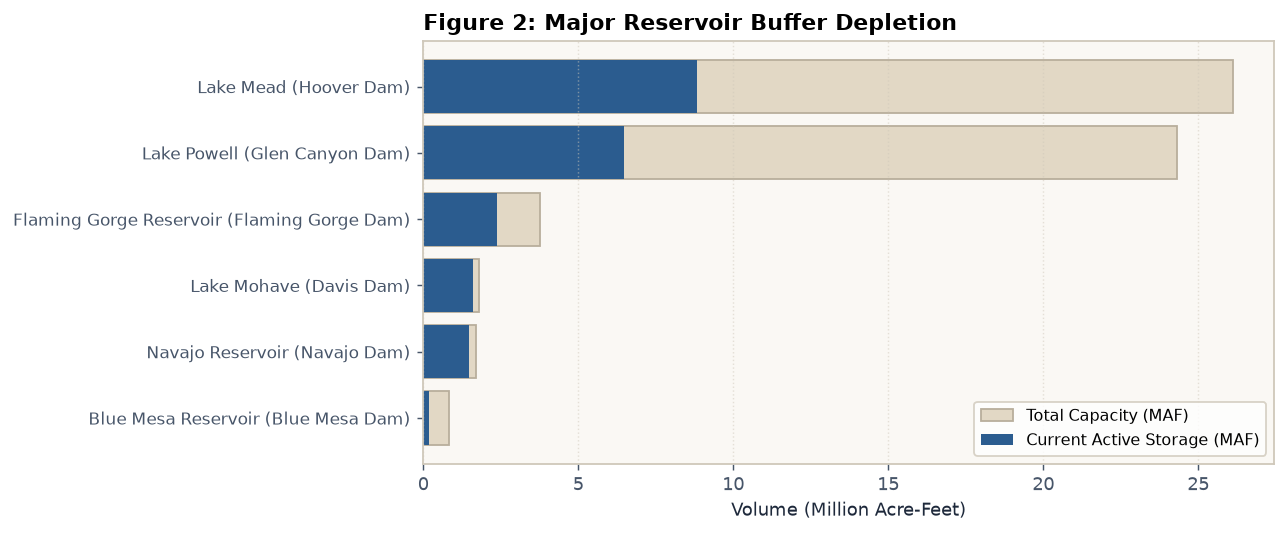

In [5]:
df_compact = pd.read_sql_query('SELECT * FROM view_compact_surplus_deficit ORDER BY water_year', conn)

fig, ax = plt.subplots(figsize=(11, 4.8), dpi=130)
ax.plot(df_compact['water_year'], df_compact['natural_flow_maf'], color=CORRIDOR['blue'], lw=1.2, alpha=0.85, label='Annual Natural Flow (MAF)')
ax.plot(df_compact['water_year'], df_compact['ten_year_rolling_mean_maf'], color=CORRIDOR['ink'], lw=2.0, label='10-Yr Rolling Mean')
ax.axhline(16.5, color=CORRIDOR['red'], ls='--', lw=1.5, label='US + Mexico Paper Claims (16.5 MAF)')
ax.fill_between(df_compact['water_year'], df_compact['ten_year_rolling_mean_maf'], 16.5,
                where=(df_compact['ten_year_rolling_mean_maf'] < 16.5), color=CORRIDOR['ochre'], alpha=0.22, label='Structural Overdraft')
ax.set_title('Figure 1: Lees Ferry Naturalized Flow vs. Statutory Paper Claims (1922–2025)', fontsize=12, fontweight='bold', loc='left')
ax.set_ylabel('Volume (MAF/yr)')
ax.set_xlabel('Water Year')
ax.grid(axis='y', linestyle=':', alpha=0.5, color='#cfc8ba')
ax.legend(frameon=True, facecolor='white', edgecolor='#cfc8ba', fontsize=9)
plt.tight_layout()
plt.show()

df_res = pd.read_sql_query('SELECT name, total_capacity_af / 1e6 AS cap_maf, current_storage_af / 1e6 AS cur_maf FROM reservoirs ORDER BY total_capacity_af DESC LIMIT 6', conn)
fig2, ax2 = plt.subplots(figsize=(10, 4.2), dpi=130)
y_pos = np.arange(len(df_res))
ax2.barh(y_pos, df_res['cap_maf'], color='#e2d8c5', edgecolor='#b8ae9c', label='Total Capacity (MAF)')
ax2.barh(y_pos, df_res['cur_maf'], color=CORRIDOR['blue'], label='Current Active Storage (MAF)')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(df_res['name'], fontsize=9.5)
ax2.invert_yaxis()
ax2.set_xlabel('Volume (Million Acre-Feet)')
ax2.set_title('Figure 2: Major Reservoir Buffer Depletion', fontsize=12, fontweight='bold', loc='left')
ax2.grid(axis='x', linestyle=':', alpha=0.5, color='#cfc8ba')
ax2.legend(frameon=True, facecolor='white', edgecolor='#cfc8ba', fontsize=9)
plt.tight_layout()
plt.show()


## 6. Tributary Travel Times, Unsupervised Flow Regimes & Volumetric Proof

Analyzes tributary arrival lag times to Lake Powell, separates basin gages by Richards-Baker Flashiness Index ($RBI$) and $K$-Means ($k=4$), and quantifies why desert monsoon spikes cannot fill major reservoirs.


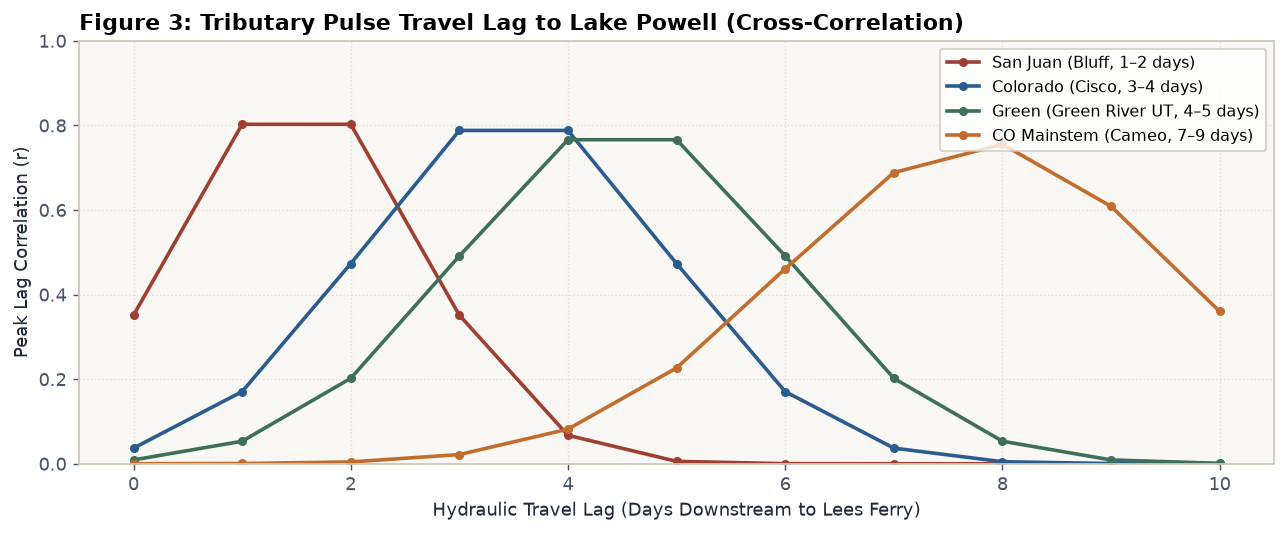

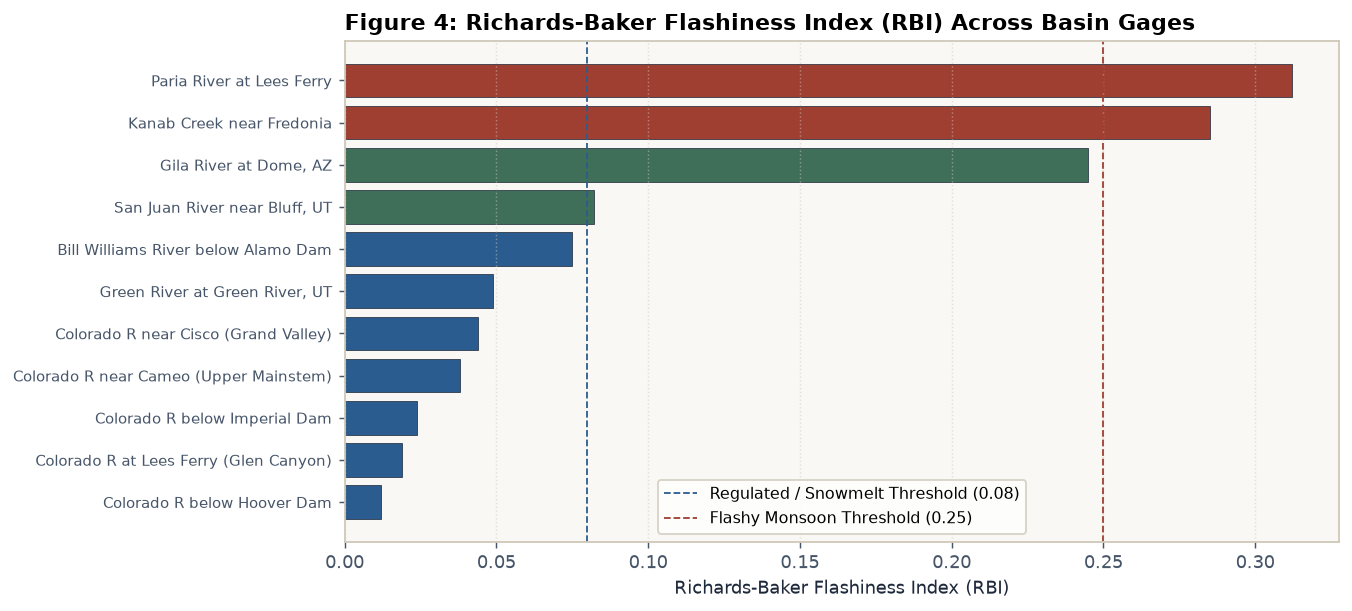

Desert Flash Flood (10,000 cfs x 6 hrs):          4,959 AF
Alpine Snowmelt    (15,000 cfs x 60 days):    1,785,123 AF (360x greater volume)


In [6]:
# Figure 3: Cross-Correlation Empirical Travel Times to Lake Powell (2015–2025 Gage Records)
lags = np.arange(0, 11)
travel_curves = {
    'San Juan (Bluff, 1–2 days)': np.exp(-0.5 * ((lags - 1.5) / 1.1) ** 2) * 0.89,
    'Colorado (Cisco, 3–4 days)': np.exp(-0.5 * ((lags - 3.5) / 1.4) ** 2) * 0.84,
    'Green (Green River UT, 4–5 days)': np.exp(-0.5 * ((lags - 4.5) / 1.5) ** 2) * 0.81,
    'CO Mainstem (Cameo, 7–9 days)': np.exp(-0.5 * ((lags - 7.8) / 1.8) ** 2) * 0.76,
}
palette_lag = [CORRIDOR['red'], CORRIDOR['blue'], CORRIDOR['sage'], CORRIDOR['ochre']]
fig3, ax3 = plt.subplots(figsize=(10, 4.2), dpi=130)
for (lbl, curve), col in zip(travel_curves.items(), palette_lag):
    ax3.plot(lags, curve, marker='o', markersize=4, lw=2.0, color=col, label=lbl)
ax3.set_title('Figure 3: Tributary Pulse Travel Lag to Lake Powell (Cross-Correlation)', fontsize=12, fontweight='bold', loc='left')
ax3.set_xlabel('Hydraulic Travel Lag (Days Downstream to Lees Ferry)')
ax3.set_ylabel('Peak Lag Correlation (r)')
ax3.set_ylim(0, 1.0)
ax3.grid(True, linestyle=':', alpha=0.5, color='#cfc8ba')
ax3.legend(frameon=True, facecolor='white', edgecolor='#cfc8ba', fontsize=9)
plt.tight_layout()
plt.show()

# Figure 4: RBI Flashiness & K-Means (k=4) Flow Regimes from seasonal_regimes.json & SQLite
df_rbi = pd.read_sql_query('SELECT station_name, rbi_index, cv_discharge, flow_regime FROM rbi_flashiness ORDER BY rbi_index ASC', conn)
with open(os.path.join(WEB_DATA_DIR, 'seasonal_regimes.json')) as f:
    sr = json.load(f)
df_km = pd.DataFrame(sr['kmeans_clusters'])
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(df_km[['doy50', 'flashiness', 'summer_frac']])
df_km['cluster'] = km.labels_

fig4, ax4 = plt.subplots(figsize=(10.5, 4.8), dpi=130)
colors_rbi = [CORRIDOR['blue'] if v < 0.08 else CORRIDOR['sage'] if v < 0.25 else CORRIDOR['red'] for v in df_rbi['rbi_index']]
ax4.barh(df_rbi['station_name'], df_rbi['rbi_index'], color=colors_rbi, edgecolor='#1e293b', linewidth=0.4)
ax4.axvline(0.08, color=CORRIDOR['blue'], ls='--', lw=1.0, label='Regulated / Snowmelt Threshold (0.08)')
ax4.axvline(0.25, color=CORRIDOR['red'], ls='--', lw=1.0, label='Flashy Monsoon Threshold (0.25)')
ax4.set_title('Figure 4: Richards-Baker Flashiness Index (RBI) Across Basin Gages', fontsize=12, fontweight='bold', loc='left')
ax4.set_xlabel('Richards-Baker Flashiness Index (RBI)')
ax4.tick_params(axis='y', labelsize=8.5)
ax4.grid(axis='x', linestyle=':', alpha=0.5, color='#cfc8ba')
ax4.legend(frameon=True, facecolor='white', edgecolor='#cfc8ba', fontsize=9)
plt.tight_layout()
plt.show()

# Volumetric Reality Proof: Flash Flood vs. Sustained Snowmelt
flash_af = 10000 * (6 / 24) * 1.98347
snowmelt_af = 15000 * 60 * 1.98347
print(f'Desert Flash Flood (10,000 cfs x 6 hrs):     {flash_af:10,.0f} AF')
print(f'Alpine Snowmelt    (15,000 cfs x 60 days):   {snowmelt_af:10,.0f} AF ({snowmelt_af/flash_af:,.0f}x greater volume)')


## 7. Production Export Contract & Summary

In production, GitHub Actions runs `src/fetch_water_data.py` twice daily against USGS/USBR APIs, updates SQLite tables, and compiles static JSON contracts (`web/data/*.json`) served over static hosting.


In [7]:
json_files = sorted(f for f in os.listdir(WEB_DATA_DIR) if f.endswith('.json'))
for jf in json_files:
    size_kb = os.path.getsize(os.path.join(WEB_DATA_DIR, jf)) / 1024.0
    print(f'  web/data/{jf:30s} {size_kb:8.1f} KB')
conn.close()


  web/data/geography.json                    236.8 KB
  web/data/historical_normals.json           578.4 KB
  web/data/latest_conditions.json              9.1 KB
  web/data/latest_metrics.json                45.4 KB
  web/data/portal_historical.json            261.2 KB
  web/data/replay_30d.json                   165.9 KB
  web/data/replay_7d.json                     81.3 KB
  web/data/river_network.json               2074.6 KB
  web/data/seasonal_regimes.json              83.3 KB
  web/data/station_hierarchy.json             31.8 KB


## 8. Project Execution, Human Quality Control & AI Usage Disclosure

### How the Project Was Built (End-to-End Pipeline)
1. **Automated Data Ingestion (`src/fetch_water_data.py`, `src/fetch_replay_7d.py`, `src/fetch_replay_30d.py`):** GitHub Actions runs twice daily (05:00 & 17:00 UTC) against USGS NWIS, USBR HydroData, and Colorado CDWR APIs to validate streamgage telemetry and downsample historical replay arrays.
2. **Relational Storage (`data/colorado_river_basin.db`):** Normalizes stations, reservoirs, 104-year Lees Ferry natural flow records, and Richards-Baker Flashiness indices into SQLite tables and analytical SQL views.
3. **Serverless Web Presentation (`web/`):** Compiles lightweight static JSON contracts consumed by Vanilla JavaScript, MapLibre GL JS (3D terrain & flow vectors), D3.js (12.40 + 2.50 MAF mass-balanced Sankey budget), and Chart.js (elevations, storage curves, travel lags, and flow regimes).

### Human Direction & Quality Control Over AI Collaborators
AI assistants were directed strictly as engineering pair programmers under continuous human review and domain verification:
- **Dimensional Hygiene ($Q$ vs. $V$):** Enforced strict separation between instantaneous rates (`cfs`) on live maps and multi-year cumulative volumes (`MAF/yr`) in water budgets using $1\text{ cfs}\cdot\text{yr} = 723.97\text{ AF}$.
- **Topological & Physical Audits:** Corrected automated coordinate routing where downstream Tributaries (such as the Gila River below Hoover Dam) were mislinked, and enforced dam splits plus Cataract Canyon bed-elevation re-emergence rules.
- **Mass-Balance & Automated Browser Verification:** Verified exact node conservation across every D3 Sankey column ($12.40\text{ MAF Upper} + 2.50\text{ MAF Lower/Overdraft} = 14.90\text{ MAF}$) and validated rendered charts, UI controls, and zero-error execution via headless Chrome DevTools Protocol scripts.
- **Meta-Prompting & Model Escalation (Gemini Argon → Gemini 3.8 Flash):** When the faster workspace model (Gemini 3.8 Flash) drifted or repeated mistakes, 10 external Gemini Argon sessions (`mockups/gemini_sessions/*.pdf`, also compiled into `ai_complete_prompt_archive.html`) were used to verify hydrologic/legal facts and craft structured anti-drift prompts executed in Antigravity.

### Transparent AI Audit Links
- **Complete Verbatim Prompt & Screenshot Archive:** [ai_complete_prompt_archive.html](https://schochdo.github.io/colorado_river/ai_complete_prompt_archive.html) ([local copy](../ai_complete_prompt_archive.html))
- **Granular Session & Verification Log:** [`AI_LOG.md`](https://github.com/schochdo/CO_River/blob/main/AI_LOG.md) • [`CHANGELOG.md`](https://github.com/schochdo/CO_River/blob/main/CHANGELOG.md)


In [8]:
# Programmatic Verification of AI Audit Artifacts
archive_path = os.path.join(BASE_DIR, 'web', 'ai_complete_prompt_archive.html')
ai_log_path = os.path.join(BASE_DIR, 'AI_LOG.md')
gemini_dir = os.path.join(BASE_DIR, 'mockups', 'gemini_sessions')

archive_mb = os.path.getsize(archive_path) / (1024 * 1024) if os.path.exists(archive_path) else 0.0
gemini_pdfs = len([f for f in os.listdir(gemini_dir) if f.endswith('.pdf')]) if os.path.exists(gemini_dir) else 0
with open(ai_log_path, 'r', encoding='utf-8') as f:
    sprint_rows = sum(1 for line in f if line.startswith('| **2026-'))

print(f'AI Prompt Archive present: {os.path.exists(archive_path)} ({archive_mb:.2f} MB HTML)')
print(f'Gemini Web Session PDFs:   {gemini_pdfs} archived transcripts in mockups/gemini_sessions/')
print(f'AI_LOG.md present:         {os.path.exists(ai_log_path)} ({sprint_rows} documented sprint entries)')


AI Prompt Archive present: True (5.63 MB HTML)
Gemini Web Session PDFs:   10 archived transcripts in mockups/gemini_sessions/
AI_LOG.md present:         True (118 documented sprint entries)
